# Settings

In [900]:
run_beamforming = True
beamform_interpolated = True

parameters_file_path = "./parameters/003_simulation_template.json"

#vein parameters
veins = 2 #number of veins
angle = [25, -25] #degrees
vein_length = [0.003, 0.003] #mm
vein_diameter = [0.0001, 0.0001] #mm
blood_density = [1200, 1200] #nb of possible globules for the vein
starting_x = [0.0036, 0.0041] #mm 40 * pitch
starting_y = [0.005, 0.005] #mm

# Imports

In [901]:
import numpy as np
import matplotlib.pyplot as plt
from numba import njit
import json

# Import parameters

In [902]:
def load_parameters(json_file_path):
    with open(json_file_path, 'r') as f:
        params = json.load(f)
    return params

In [903]:
def add_extra_params(params):
    
    params["rf"]["upsampled_samples"] = params["rf"]["samples"] + (params["rf"]["interpolation_factor"] - 1) * (params["rf"]["samples"] - 1)
    params["rf"]["upsampled_sampling_rate"] = params["rf"]["sampling_rate"] * params["rf"]["interpolation_factor"]

    return params

In [904]:
params = load_parameters(parameters_file_path)
params = add_extra_params(params)

pos = np.linspace(start=0, stop=params["array"]["length"], num=params["array"]["length"], dtype=int) #array position sampling
time = np.linspace(start=0, stop=1 / params["rf"]["sampling_rate"] * params["rf"]["samples"], num=params["rf"]["samples"]) #time sampling
C = 1500 #speed of sound
frames = params["image"]["nframes"]

print(f"Max acquisition depth : {C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2} m") #v = d / t => d = v * t / 2 (round trip) with t = sample_step * samples

Max acquisition depth : 0.010008000000000001 m


# Creating reflector object

In [905]:
def create_vein(starting_x, starting_y, vein_length, vein_diameter, angle, blood_density, params):

    virtual_space = np.zeros((params["rf"]["samples"], params["array"]["length"]))

    vein = np.random.rand(int(np.sqrt(blood_density)), int(np.sqrt(blood_density)))

    for i in range(vein.shape[0]):
        for j in range(vein.shape[1]):
            if vein[i][j] >= 0.5:
                vein[i][j] = 1
            else:
                vein[i][j] = 0

    starting_x_idx = int(starting_x / params["array"]["pitch"]) #position / step gives the index
    starting_y_idx = int((starting_y / C) * params["rf"]["sampling_rate"]) #position / step gives the index

    for i in range(0, vein.shape[0]):
        for j in range(0, vein.shape[1]):
            x_pos = (i * (vein_length / vein.shape[0])) * np.sin(angle * np.pi / 180) + (j * (vein_diameter / vein.shape[0])) * np.sin((90 - angle) * np.pi / 180)
            y_pos = (i * (vein_length / vein.shape[0])) * np.cos(angle * np.pi / 180) + (j * (vein_diameter / vein.shape[0])) * np.cos((90 - angle) * np.pi / 180)

            x_idx = int(x_pos / params["array"]["pitch"])
            y_idx = int((y_pos / C) * params["rf"]["sampling_rate"])

            virtual_space[starting_y_idx + y_idx, starting_x_idx + x_idx] = vein[i][j]

    return virtual_space

In [906]:
vein_temporal_space = np.zeros((params["rf"]["samples"], params["array"]["length"], frames))

for i in range(frames):
    for j in range(veins):
        vein_temporal_space[:,:,i] += create_vein(starting_x[j], starting_y[j], vein_length[j], vein_diameter[j], angle[j], blood_density[j], params)

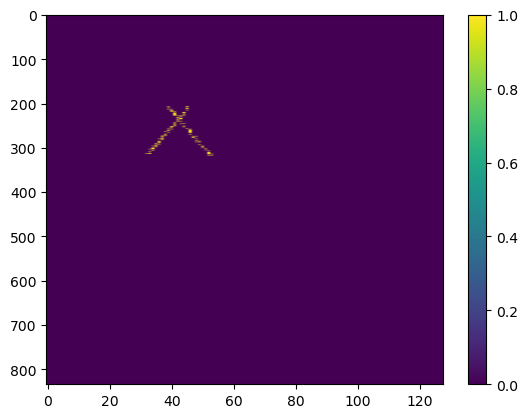

In [908]:
plt.imshow(vein_temporal_space[:,:,0], aspect='auto')
plt.colorbar()
plt.show()

# Convert to spacial domain

In [909]:
def convert_to_image_space(virtual_space, params, frames):

    max_depth = C * (1 / params["rf"]["sampling_rate"] * params["rf"]["samples"]) / 2
    print(f"Max depth : {max_depth} m")
    max_length = params["array"]["length"] * params["array"]["pitch"]
    print(f"Max length : {max_length} m")

    position_matrix = np.zeros((int(max_depth / params["image"]["dz"]), int(max_length / params["image"]["dx"]), frames))

    for h in range(frames):
        for i in range(0, virtual_space.shape[0]):
            for j in range(0, virtual_space.shape[1]):
                if virtual_space[i][j][h] != 0:

                    depth_idx_value = i *( 1 / params["rf"]["sampling_rate"]) * C #find the depth in meters for virtual space
                    length_idx_value = j * params["array"]["pitch"] #find the length in meters for virtual space

                    depth_idx = int(depth_idx_value / params["image"]["dz"]) #find the corresponding index in the image space
                    length_idx = int(length_idx_value / params["image"]["dx"]) #find the corresponding index in the image space

                    position_matrix[depth_idx, length_idx, h] = 1

    return position_matrix

In [910]:
position_matrix = convert_to_image_space(vein_temporal_space, params, frames)

Max depth : 0.010008000000000001 m
Max length : 0.01152 m


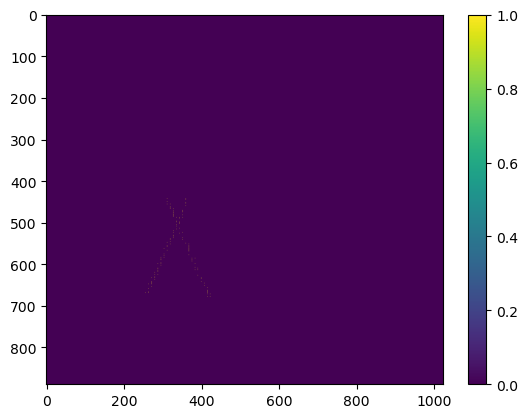

In [ ]:
#plotting the position matrix
plt.imshow(position_matrix[:,:,0], aspect='auto', cmap="viridis")
plt.colorbar()

plt.show()

# Convert to JSON objects

In [913]:
def save_objects_to_json(matrix, parameters, new_file_path):

    parameters["objects"] = []

    for h in range(matrix.shape[2]):
        parameters["objects"].append([])
        for i in range(0, matrix.shape[0]):
            for j in range(0, matrix.shape[1]):
                if matrix[i][j][h] != 0:
                    parameters["objects"][h].append({"position": j * parameters["image"]["dx"], "depth": i * parameters["image"]["dz"]})

    with open(new_file_path, 'w') as f:
        json.dump(parameters, f, indent=4)

    return parameters

In [914]:
new_params = save_objects_to_json(position_matrix, params, "./parameters/003_simulation_test.json")
print(f"Saved a total of {len(new_params['objects'])} objects to the json file")

Saved a total of 1 objects to the json file
